<a href="https://colab.research.google.com/github/Renyambar/PCVK26_23_Reny/blob/main/Week9_23.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##NAMA  : RENY AMBARWATI
##NIM   : 244107020066
##KELAS : TI-3F


## Langkah 1: Menghubungkan Google Colab dengan Google Drive

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Langkah 2: Import Library Utama

In [4]:
import cv2
import numpy as np
from matplotlib import pyplot as plt
# Daftar 2 citra utama
daftar_citra = [
    ('Plat Nomer', '/content/drive/MyDrive/PCVK /Image Jobsheet/plat.jpeg'),
    ('Morp', '/content/drive/MyDrive/PCVK /Image Jobsheet/noisy_text.png')
]

##Langkah 3: Operasi Dilasi Tanpa Library Morphology OpenCV

In [5]:
def dilasi_citra(F, w):
    # size image
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate structure element dilasi (SED)
    SED = np.ones((w, w), dtype=np.uint8)
    constant1 = (w - 1) // 2

    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

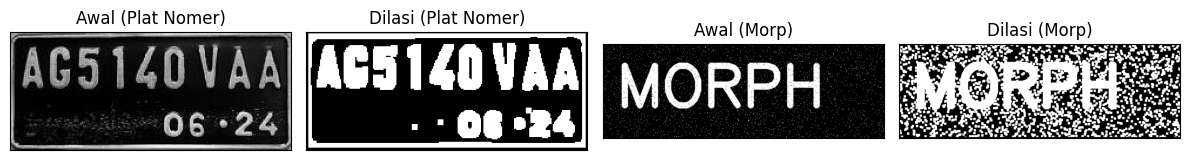

In [6]:
w = 5
plt.figure(figsize=(12, 3))
for idx, (nama, path) in enumerate(daftar_citra):
    img_d = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    ret, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)
    imgD = dilasi_citra(thresh, w)

    plt.subplot(1, 4, idx * 2 + 1), plt.imshow(img_d, cmap='gray')
    plt.title(f'Awal ({nama})'), plt.xticks([]), plt.yticks([])
    plt.subplot(1, 4, idx * 2 + 2), plt.imshow(imgD, cmap='gray')
    plt.title(f'Dilasi ({nama})'), plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

## Langkah 4: Operasi Dilasi Menggunakan Library Morphology OpenCV

[[1 1 1]
 [1 1 1]
 [1 1 1]]


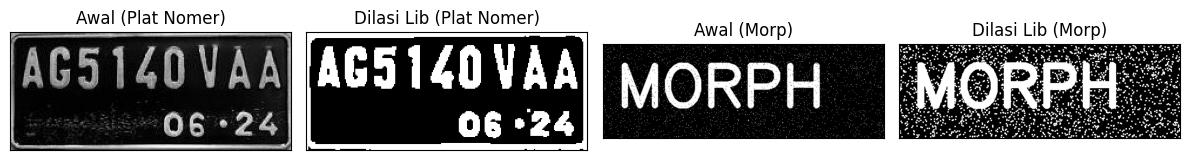

In [7]:
kernel = np.ones((3, 3), np.uint16)
print(kernel)

plt.figure(figsize=(12, 3))
for idx, (nama, path) in enumerate(daftar_citra):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
    dilasi = cv2.dilate(thresh, kernel, iterations=1)

    plt.subplot(1, 4, idx * 2 + 1), plt.imshow(img, cmap='gray')
    plt.title(f'Awal ({nama})'), plt.xticks([]), plt.yticks([])
    plt.subplot(1, 4, idx * 2 + 2), plt.imshow(dilasi, cmap='gray')
    plt.title(f'Dilasi Lib ({nama})'), plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

## Langkah 5: Operasi Erosi Menggunakan Fungsi Manual (Tanpa Library) dengan SE Square 5x5

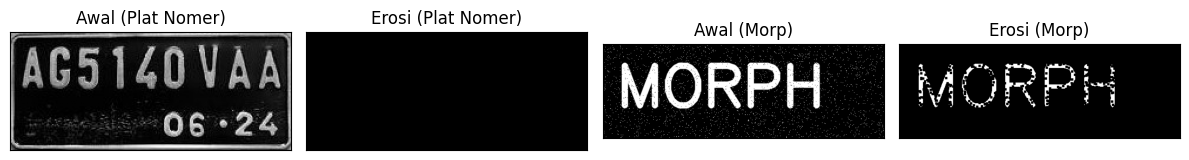

In [10]:
# Erosi Tanpa Library dengan looping pada 2 citra (Plat Nomer & Morp)
def erosi_citra(F, k):
    # size image
    m, n = F.shape

    # Generate structure element erosi (SE)
    SE = np.ones((k, k), dtype=np.uint8)
    constant = (k - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant, m-constant):
      for j in range(constant,n-constant):
        temp= F[i-constant:i+constant+1, j-constant:j+constant+1]
        product= temp*SE
        imgE[i,j]= np.min(product)
    return imgE

k = 5
plt.figure(figsize=(12, 3))
for idx, (nama, path) in enumerate(daftar_citra):
    img_e = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    ret1, thresh1 = cv2.threshold(img_e, 175, 225, cv2.THRESH_BINARY)
    imgE = erosi_citra(thresh1, k)

    plt.subplot(1, 4, idx * 2 + 1), plt.imshow(img_e, cmap='gray')
    plt.title(f'Awal ({nama})'), plt.xticks([]), plt.yticks([])
    plt.subplot(1, 4, idx * 2 + 2), plt.imshow(imgE, cmap='gray')
    plt.title(f'Erosi ({nama})'), plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

## Langkah 6: Operasi Erosi Menggunakan Library OpenCV SE Square 5x5 (Looping 2 Citra)

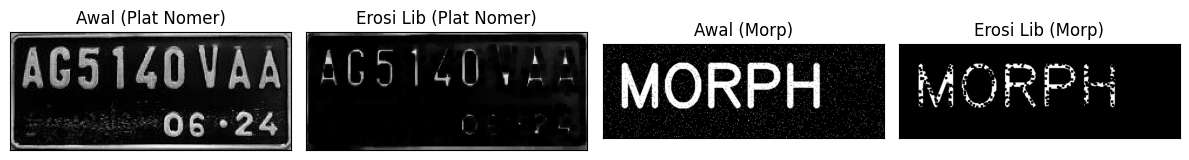

In [9]:
# EROSI LIBRARY
kernel = np.ones((5, 5), np.uint8)

plt.figure(figsize=(12, 3))
for idx, (nama, path) in enumerate(daftar_citra):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    erosion = cv2.erode(img, kernel, iterations=1)

    plt.subplot(1, 4, idx * 2 + 1), plt.imshow(img, cmap='gray')
    plt.title(f'Awal ({nama})'), plt.xticks([]), plt.yticks([])
    plt.subplot(1, 4, idx * 2 + 2), plt.imshow(erosion, cmap='gray')
    plt.title(f'Erosi Lib ({nama})'), plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

## Langkah 7: Operasi Opening Tanpa dan Dengan Library OpenCV

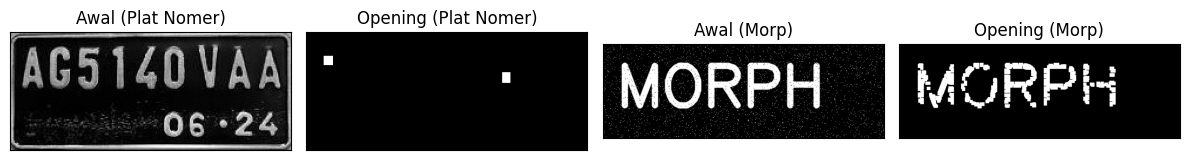

In [11]:
# Operasi Opening Tanpa Library Morphology
k = 7
plt.figure(figsize=(12, 3))
for idx, (nama, path) in enumerate(daftar_citra):
    img_o = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    reto, thresho = cv2.threshold(img_o, 127, 225, cv2.THRESH_BINARY)
    imgO = dilasi_citra(erosi_citra(thresho, k), k)

    plt.subplot(1, 4, idx * 2 + 1), plt.imshow(img_o, cmap='gray')
    plt.title(f'Awal ({nama})'), plt.xticks([]), plt.yticks([])
    plt.subplot(1, 4, idx * 2 + 2), plt.imshow(imgO, cmap='gray')
    plt.title(f'Opening ({nama})'), plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

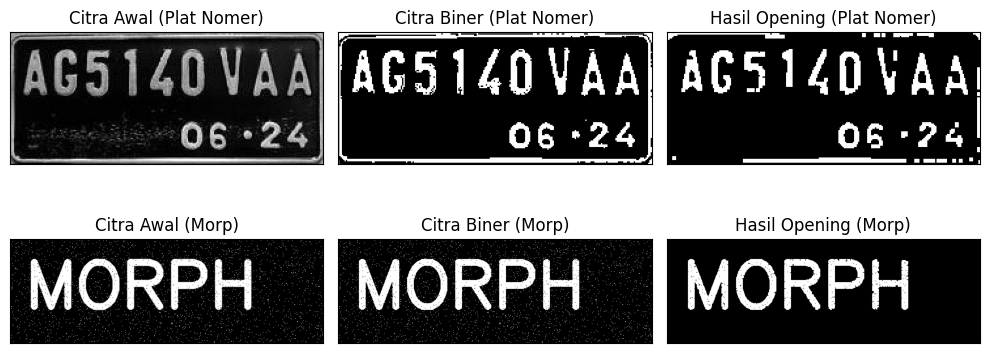

In [12]:
# Operasi Opening Menggunakan Library Morphology
kernel = np.ones((3, 3), np.uint8)

plt.figure(figsize=(10, 4.5))
for idx, (nama, path) in enumerate(daftar_citra):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
    openn = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)

    plt.subplot(2, 3, idx * 3 + 1), plt.imshow(img, cmap='gray')
    plt.title(f'Citra Awal ({nama})'), plt.xticks([]), plt.yticks([])
    plt.subplot(2, 3, idx * 3 + 2), plt.imshow(thresh, cmap='gray')
    plt.title(f'Citra Biner ({nama})'), plt.xticks([]), plt.yticks([])
    plt.subplot(2, 3, idx * 3 + 3), plt.imshow(openn, cmap='gray')
    plt.title(f'Hasil Opening ({nama})'), plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

## Langkah 8: Operasi Closing Tanpa dan Dengan Library OpenCV

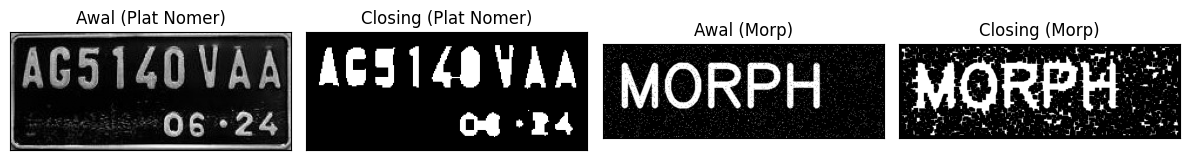

In [13]:
# Operasi Closing Tanpa Library Morphology
k = 7
plt.figure(figsize=(12, 3))
for idx, (nama, path) in enumerate(daftar_citra):
    img_c = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    retc, threshc = cv2.threshold(img_c, 127, 225, cv2.THRESH_BINARY)
    imgC = erosi_citra(dilasi_citra(threshc, k), k)

    plt.subplot(1, 4, idx * 2 + 1), plt.imshow(img_c, cmap='gray')
    plt.title(f'Awal ({nama})'), plt.xticks([]), plt.yticks([])
    plt.subplot(1, 4, idx * 2 + 2), plt.imshow(imgC, cmap='gray')
    plt.title(f'Closing ({nama})'), plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

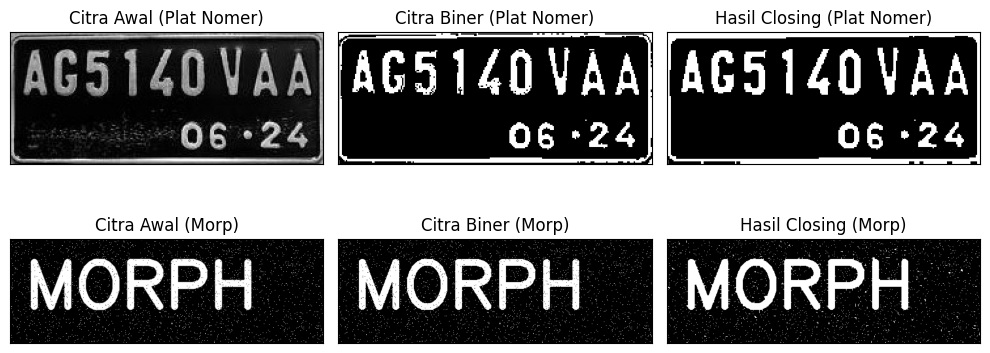

In [14]:
# Operasi Closing Dengan Library Morphology
kernel = np.ones((3, 3), np.uint8)

plt.figure(figsize=(10, 4.5))
for idx, (nama, path) in enumerate(daftar_citra):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
    closs = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

    plt.subplot(2, 3, idx * 3 + 1), plt.imshow(img, cmap='gray')
    plt.title(f'Citra Awal ({nama})'), plt.xticks([]), plt.yticks([])
    plt.subplot(2, 3, idx * 3 + 2), plt.imshow(thresh, cmap='gray')
    plt.title(f'Citra Biner ({nama})'), plt.xticks([]), plt.yticks([])
    plt.subplot(2, 3, idx * 3 + 3), plt.imshow(closs, cmap='gray')
    plt.title(f'Hasil Closing ({nama})'), plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

## Langkah 9: Operasi Dilasi dengan Structuring Element Cross 3x3 dan 5x5

SED = Cross 3
SED = Cross 5


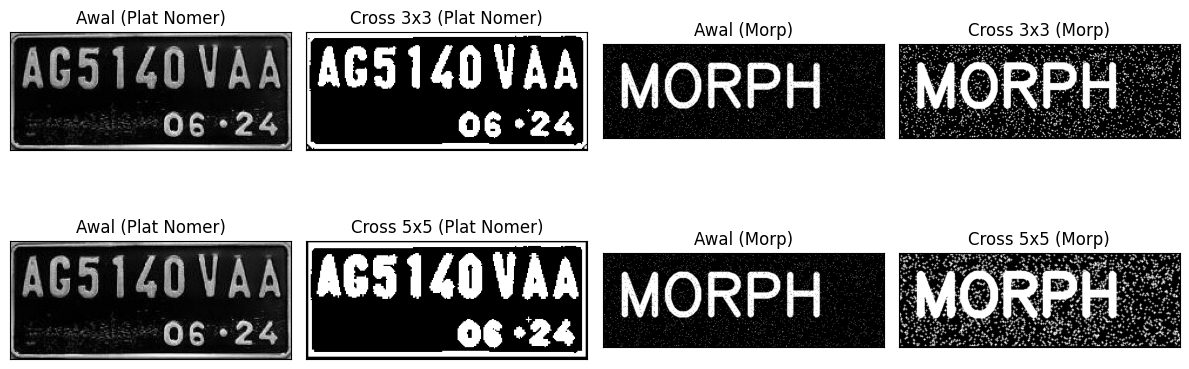

In [15]:
# Dilasi Cross SED 3x3 dan 5x5
def dilasi_citra_cross(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    if w == 3:
        SED = np.array([[0, 1, 0],
                        [1, 1, 1],
                        [0, 1, 0]], dtype=np.uint8)
    else:
        SED = np.array([[0, 0, 1, 0, 0],
                        [0, 0, 1, 0, 0],
                        [1, 1, 1, 1, 1],
                        [0, 0, 1, 0, 0],
                        [0, 0, 1, 0, 0]], dtype=np.uint8)
    constant1 = (w - 1) // 2
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

plt.figure(figsize=(12, 5))
for row_idx, w in enumerate([3, 5]):
    print(f'SED = Cross {w}')
    for idx, (nama, path) in enumerate(daftar_citra):
        img_d = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
        imgD = dilasi_citra_cross(thresh, w)

        pos = row_idx * 4 + idx * 2 + 1
        plt.subplot(2, 4, pos), plt.imshow(img_d, cmap='gray')
        plt.title(f'Awal ({nama})'), plt.xticks([]), plt.yticks([])
        plt.subplot(2, 4, pos + 1), plt.imshow(imgD, cmap='gray')
        plt.title(f'Cross {w}x{w} ({nama})'), plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

## Langkah 10: Operasi Dilasi dengan Structuring Element Circular 3x3 dan 5x5

SED = Circle 3
SED = Circle 5


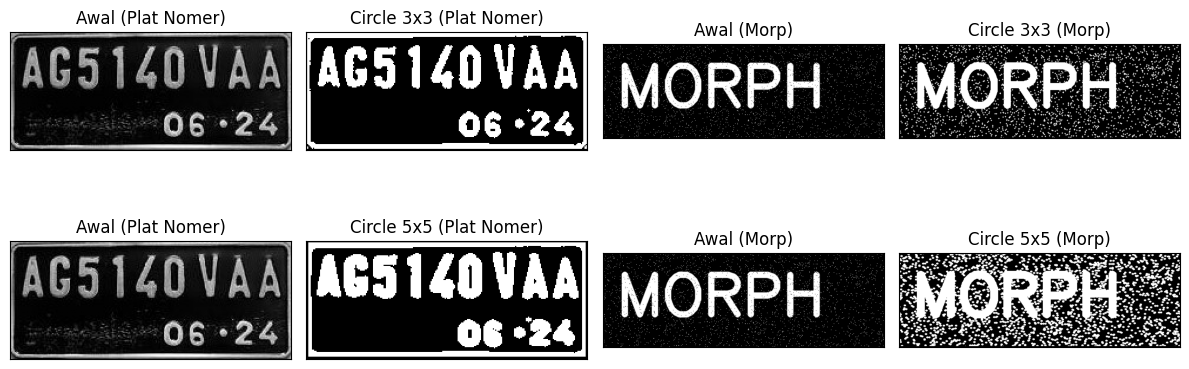

In [16]:
# Dilasi Circular SED 3x3 dan 5x5
def dilasi_citra_circle(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    SED = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (w, w))
    constant1 = (w - 1) // 2
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

plt.figure(figsize=(12, 5))
for row_idx, w in enumerate([3, 5]):
    print(f'SED = Circle {w}')
    for idx, (nama, path) in enumerate(daftar_citra):
        img_d = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
        imgD = dilasi_citra_circle(thresh, w)

        pos = row_idx * 4 + idx * 2 + 1
        plt.subplot(2, 4, pos), plt.imshow(img_d, cmap='gray')
        plt.title(f'Awal ({nama})'), plt.xticks([]), plt.yticks([])
        plt.subplot(2, 4, pos + 1), plt.imshow(imgD, cmap='gray')
        plt.title(f'Circle {w}x{w} ({nama})'), plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

## Langkah 11: Operasi Erosi dengan Structuring Element Rectangle 3x5 dan 5x7

SE = Rectangle 3x5
SE = Rectangle 5x7


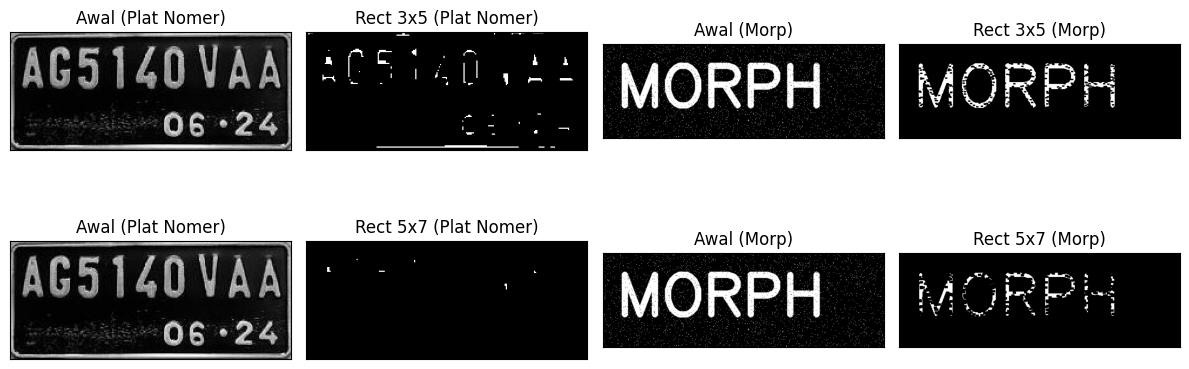

In [17]:
# Erosi Rectangle SE 3x5 dan 5x7
def erosi_citra_rect(F, p, l):
    m, n = F.shape
    SE = cv2.getStructuringElement(cv2.MORPH_RECT, (p, l))
    constant1 = (l - 1) // 2
    constant2 = (p - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)

    for i in range(constant1, m - constant1):
        for j in range(constant2, n - constant2):
            temp = F[i - constant1:i + constant1 + 1, j - constant2:j + constant2 + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE

plt.figure(figsize=(12, 5))
for row_idx, (l, p) in enumerate([(3, 5), (5, 7)]):
    print(f'SE = Rectangle {l}x{p}')
    for idx, (nama, path) in enumerate(daftar_citra):
        img_e = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
        imgE = erosi_citra_rect(thresh1, p, l)

        pos = row_idx * 4 + idx * 2 + 1
        plt.subplot(2, 4, pos), plt.imshow(img_e, cmap='gray')
        plt.title(f'Awal ({nama})'), plt.xticks([]), plt.yticks([])
        plt.subplot(2, 4, pos + 1), plt.imshow(imgE, cmap='gray')
        plt.title(f'Rect {l}x{p} ({nama})'), plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

## Langkah 12: Operasi Erosi dengan Structuring Element Line Vertikal 3 dan 5

SE = Line Vertikal 3
SE = Line Vertikal 5


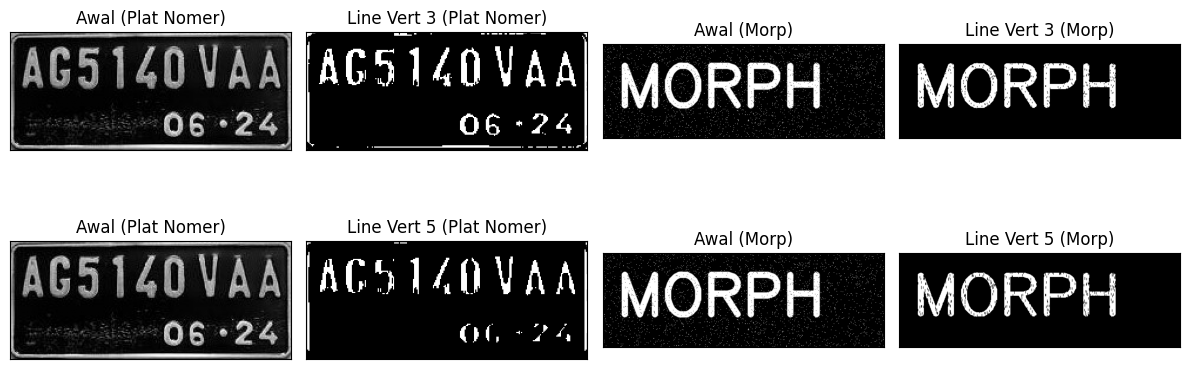

In [18]:
# Erosi Line Vertikal SE 3 dan 5
def erosi_citra_line_vertikal(F, k):
    m, n = F.shape
    SE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (1, k))
    constant = (k - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)

    for i in range(constant, m - constant):
        for j in range(0, n):
            temp = F[i - constant:i + constant + 1, j:j + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE

plt.figure(figsize=(12, 5))
for row_idx, k in enumerate([3, 5]):
    print(f'SE = Line Vertikal {k}')
    for idx, (nama, path) in enumerate(daftar_citra):
        img_e = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
        imgE = erosi_citra_line_vertikal(thresh1, k)

        pos = row_idx * 4 + idx * 2 + 1
        plt.subplot(2, 4, pos), plt.imshow(img_e, cmap='gray')
        plt.title(f'Awal ({nama})'), plt.xticks([]), plt.yticks([])
        plt.subplot(2, 4, pos + 1), plt.imshow(imgE, cmap='gray')
        plt.title(f'Line Vert {k} ({nama})'), plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()


## Langkah 13: Transformasi Top-Hat dengan Structuring Element 3x3

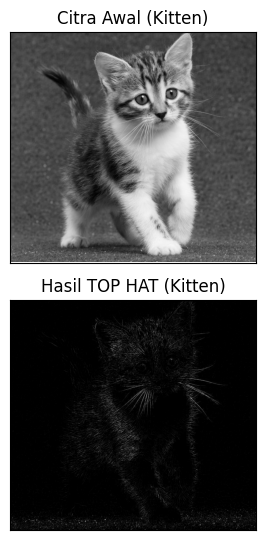

In [20]:
# Transformasi Top-Hat (SE 3x3)
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

daftar_citra_tophat = [
    ('Kitten', '/content/drive/MyDrive/PCVK /Image Jobsheet/kitten01 (1).jpg')
]

plt.figure(figsize=(12, 5.5))
for idx, (nama, path) in enumerate(daftar_citra_tophat):
    img = cv2.imread(path)
    img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    tophat_img = cv2.morphologyEx(img_gray, cv2.MORPH_TOPHAT, kernel)

    plt.subplot(2, 3, idx + 1), plt.imshow(img_gray, cmap='gray')
    plt.title(f'Citra Awal ({nama})'), plt.xticks([]), plt.yticks([])
    plt.subplot(2, 3, idx + 4), plt.imshow(tophat_img, cmap='gray')
    plt.title(f'Hasil TOP HAT ({nama})'), plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

## Langkah 14: Transformasi Black-Hat dengan Structuring Element 3x3 dan 13x5

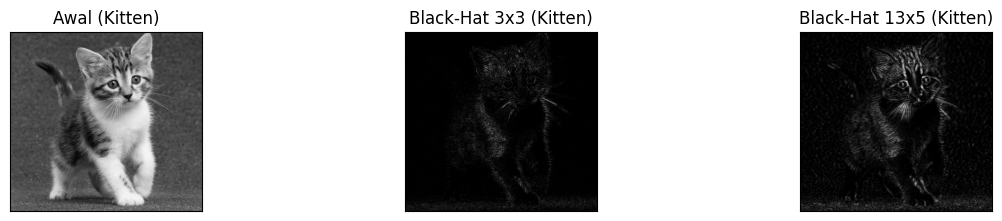

In [21]:
# Transformasi Black-Hat (SE 3x3 & SE 13x5)
kernel_3x3 = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
Kernel_13x5 = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))

plt.figure(figsize=(12, 6.2))
for idx, (nama, path) in enumerate(daftar_citra_tophat):
    img = cv2.imread(path)
    img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    blackhat_3x3 = cv2.morphologyEx(img_gray, cv2.MORPH_BLACKHAT, kernel_3x3)
    blackhat_13x5 = cv2.morphologyEx(img_gray, cv2.MORPH_BLACKHAT, Kernel_13x5)

    plt.subplot(3, 3, idx * 3 + 1), plt.imshow(img_gray, cmap='gray')
    plt.title(f'Awal ({nama})'), plt.xticks([]), plt.yticks([])
    plt.subplot(3, 3, idx * 3 + 2), plt.imshow(blackhat_3x3, cmap='gray')
    plt.title(f'Black-Hat 3x3 ({nama})'), plt.xticks([]), plt.yticks([])
    plt.subplot(3, 3, idx * 3 + 3), plt.imshow(blackhat_13x5, cmap='gray')
    plt.title(f'Black-Hat 13x5 ({nama})'), plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

## Langkah 15: Program Skeleton pada Citra Biner

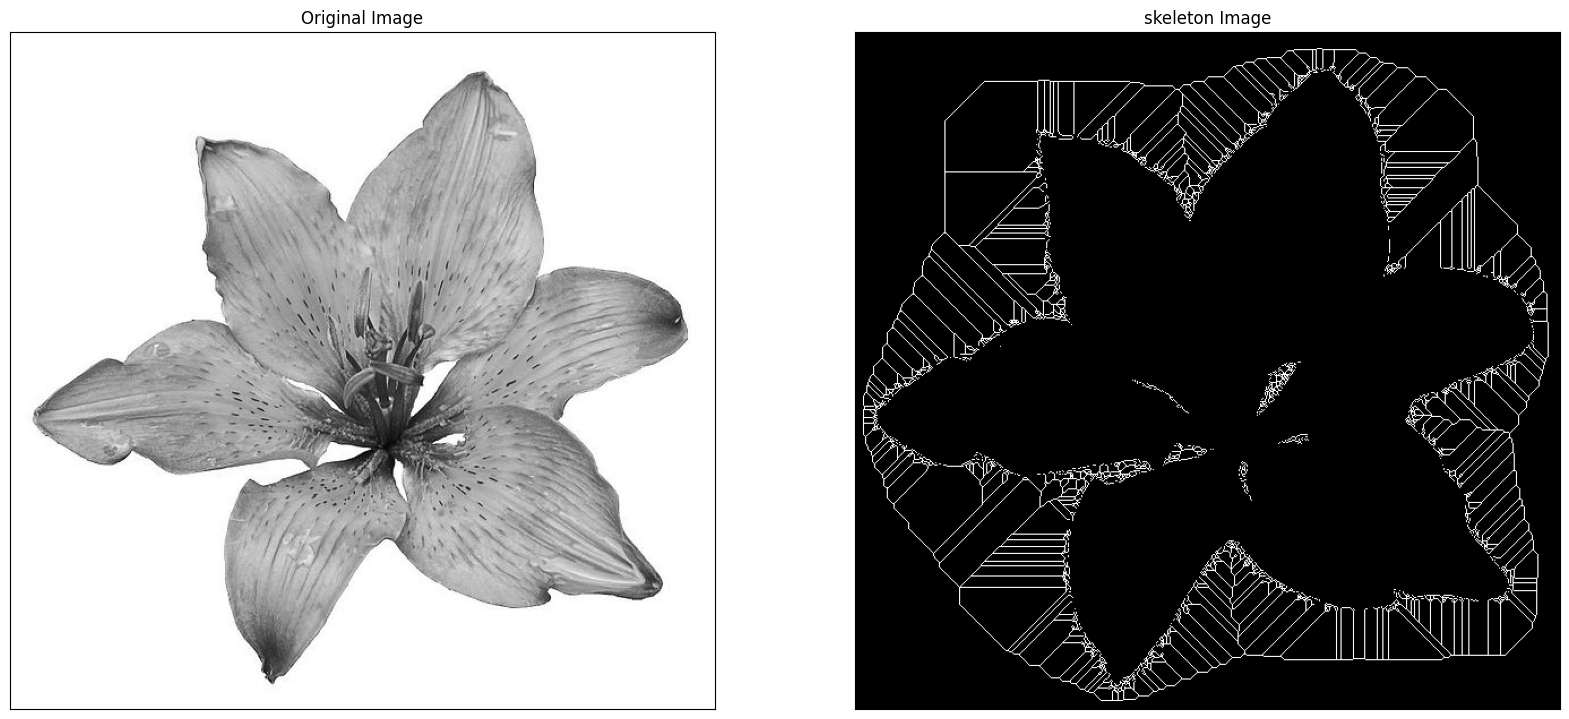

In [22]:
import cv2 as cv
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

# read image
img = cv.imread('/content/drive/MyDrive/PCVK /Image Jobsheet/lily.jpg', cv.IMREAD_GRAYSCALE)

binary = img > filters.threshold_triangle(img)

# true false to one
binary_cp = binary.copy()
binary_cp[binary_cp == True] = 1
binary_cp[binary_cp == False] = 0

# skeletonize image
skeleton = skeletonize(binary_cp)

# print images
plt.figure(figsize=(20, 20))
plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('Original Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(skeleton, cmap='gray')
plt.title('skeleton Image'), plt.xticks([]), plt.yticks([])
plt.savefig("binary and bin_skeleton.png")
plt.show()

## Langkah 16: Program Skeleton pada Citra Hasil Inversi

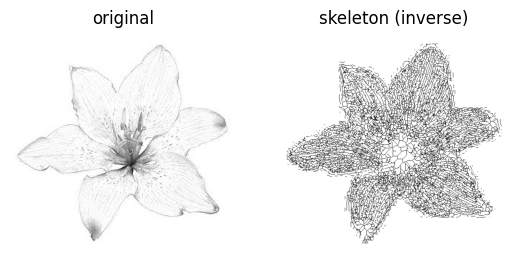

In [23]:
from skimage import io
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

# read image
img = io.imread('/content/drive/MyDrive/PCVK /Image Jobsheet/lily.jpg')[..., 0]

# Note: we want the black bits to be True, so use <
binary = img < filters.threshold_triangle(img)

# skeletonize image
skeleton = skeletonize(binary)

# print images
fig, ax = plt.subplots(1, 2)
ax[0].imshow(img, cmap='gray')
ax[0].set_title('original')
ax[0].set_axis_off()

# note the reversed colormap, gray_r
ax[1].imshow(skeleton, cmap='gray_r')
ax[1].set_title('skeleton (inverse)')
ax[1].set_axis_off()

plt.show()

## Langkah 17: Program Thinning Memakai `morphology.thin()` & Perbandingannya dengan Skeleton

Text(0.5, 1.0, 'Thin')

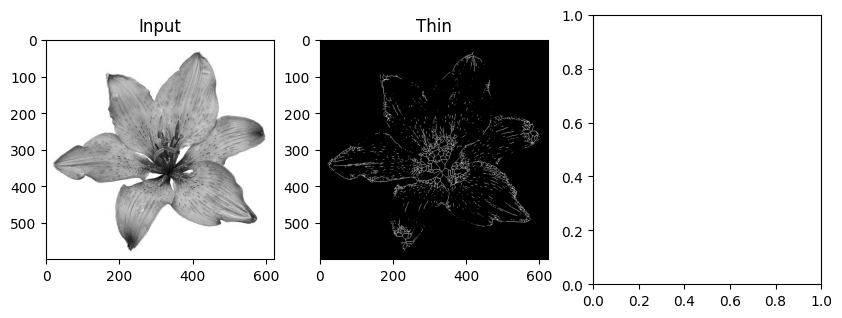

In [24]:
from skimage import img_as_float
from skimage import io, color, morphology
import matplotlib.pyplot as plt

image = img_as_float(color.rgb2gray(io.imread('/content/drive/MyDrive/PCVK /Image Jobsheet/lily.jpg')))
image_binary = image < 0.5
out_skeletonize = morphology.skeletonize(image_binary)
out_thin = morphology.thin(image_binary)

f, (ax0, ax1, ax2) = plt.subplots(1, 3, figsize=(10, 3.5))

ax0.imshow(image, cmap='gray')
ax0.set_title('Input')

ax1.imshow(out_thin, cmap='gray')
ax1.set_title('Thin')